# Demonstration of WSO Calculation

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.constants import gas_constant

# key thermodyanmic parameters
RT = 298.15 * (1e-3 * gas_constant)
beta = 1 / RT

# load dataset and structure directory
fold_rate_db = pd.read_csv("../data/fold_kinetics_dataset.csv")
struct_dir = Path("../data/PDB/")

# Implementation of WSO

In [ ]:
import os
from itertools import combinations

import mdtraj


def get_wso(
    pdbfile: str | os.PathLike, lcut: int = 2, epsilon: float = np.log(2) * RT
) -> float:
    """Implementation of the WSO parameter derived by Abdulqader & Munoz.

    Args:
        pdbfile (str | os.PathLike): Path to PDB file, assumed to be a single chain file.
        lcut (int, optional): Minimum sequence distance, any sequence distance less than or
            equal to `lcut` is omitted. Defaults to 2.
        epsilon (float, optional): Epsilon parameter for Lennard Jones potential. Defaults
            to np.log(2)*RT inorder to fully replicate contact order.

    Returns:
        float: Weighted Sequence Order (WSO) of the given PDB file.
    """
    # load PDB and omit any waters
    traj = mdtraj.load(pdbfile)
    traj = traj.atom_slice(
        atom_indices=np.array(
            [
                i
                for i in range(traj.n_atoms)
                if traj.topology.atom(i).element.name != "hydrogen"
            ]
        )
    )

    # prepare indexes
    residue_index = np.array(
        [traj.topology.atom(i).residue.index for i in range(traj.n_atoms)]
    )
    atom_radii = np.array(
        [traj.topology.atom(i).element.radius for i in range(traj.n_atoms)]
    )
    atom_pairs = np.array(list(combinations(np.arange(traj.n_atoms), r=2)))
    seqdist = np.abs(residue_index[atom_pairs][:, 0] - residue_index[atom_pairs][:, 1])
    valid_atom_pairs = atom_pairs[seqdist > lcut]
    valid_seqdist = seqdist[seqdist > lcut]

    # get distances
    r = mdtraj.compute_distances(traj=traj, atom_pairs=valid_atom_pairs)[0]
    rmin = atom_radii[valid_atom_pairs].sum(axis=1)

    # implement wso
    lj = lambda x: epsilon * ((x**12) - (2 * x**6))
    w = np.exp(-beta * lj(rmin / r)) - 1
    p = w / w.sum()

    return (p * valid_seqdist).sum()

# collect wso
wso = np.array([get_wso(struct_dir / file) for file in fold_rate_db.PDB.values])

# Demonstation Plot Showcasing WSO Correlation of $\ln(k_f)$

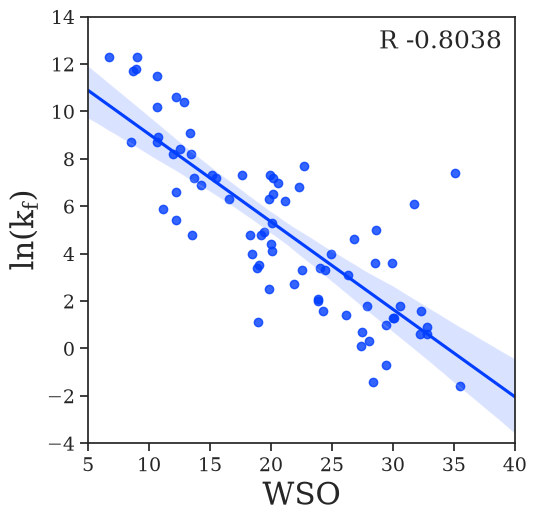

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# set seaborn themes
custom_parameters = {
    "axes.labelsize": 22,
    "axes.titlesize": 22,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "mathtext.fontset": "dejavuserif",
    "mathtext.default": "regular",
}
# set figure context
sns.set_theme(
    style="ticks",
    context="notebook",
    palette="bright",
    font="serif",
    rc=custom_parameters,
)

# plot results
fig, ax = plt.subplots(1, 1, figsize=(5.5, 5.5))
ax.axis([5, 40, -4, 14])
ax.set_aspect(35 / 18)
ax = sns.regplot(data=fold_rate_db, x=wso, y="ln_kf", truncate=False, ax=ax)
ax.set_xlabel(r"WSO")
ax.set_ylabel(r"$\ln(k_f)$")
ax.annotate(
    text=f"R {np.corrcoef(wso, fold_rate_db.ln_kf.values)[0, 1]:+0.4f}",
    xycoords="axes fraction",
    xy=(0.97, 0.97),
    ha="right",
    va="top",
    fontsize=18,
)

plt.tight_layout()
plt.show()